# NB02 — Atmospheric neutrino flux at Kamioka (HKKM 2014)

The atmospheric-neutrino backgrounds are weighted by the flux, not generated from it: each generated event carries flux × cross-section / generation density. This notebook checks the flux reader `hk_sunu_sim.flux` before it is used for weights.

- **Source:** Honda et al., PRD 92, 023004 (2015), tables for Kamioka, 20 bins in cos θ_z, azimuth-averaged, solar minimum and maximum. They are downloaded from the authors' page and **not redistributed**: put `kam-ally-20-01-sol{min,max}.d.gz` in `data/flux/hkkm2014/`.
- **Range:** 0.1 GeV – 10 TeV. The DSNB backgrounds come from E_ν ~ 0.1–few GeV.
- **Not included yet:** oscillations (step C1 of the plan); these are unoscillated fluxes.

Convention: θ_z is the zenith angle of the neutrino arrival direction, cos θ_z = +1 for down-going.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hk_sunu_sim import flux
from hk_sunu_sim.plotting import MUTED, SERIES, style, use_style

use_style()
tab = {s: flux.load(s) for s in ("min", "max")}
FLAVOURS = {14: "ν_μ", -14: "ν̄_μ", 12: "ν_e", -12: "ν̄_e"}
E = np.logspace(2, 4, 200)                     # MeV, 0.1-10 GeV
phi = {s: {p: t.flux_solid_angle_integrated(p, E) for p in FLAVOURS} for s, t in tab.items()}
print(f"table: {tab['min'].e[0]:.0f} MeV - {tab['min'].e[-1] / 1e3:.0f} GeV, {len(tab['min'].e)} energies, "
      f"{len(tab['min'].cos_edges) - 1} cos bins")

table: 100 MeV - 10000 GeV, 101 energies, 20 cos bins


## 1. Energy spectra

E · dΦ/dE integrated over all directions, solar minimum. Below 100 MeV the table does not exist: the thin, faded lines are the log-log extrapolation of `flux(..., extrapolate=True)`, a **placeholder** only.

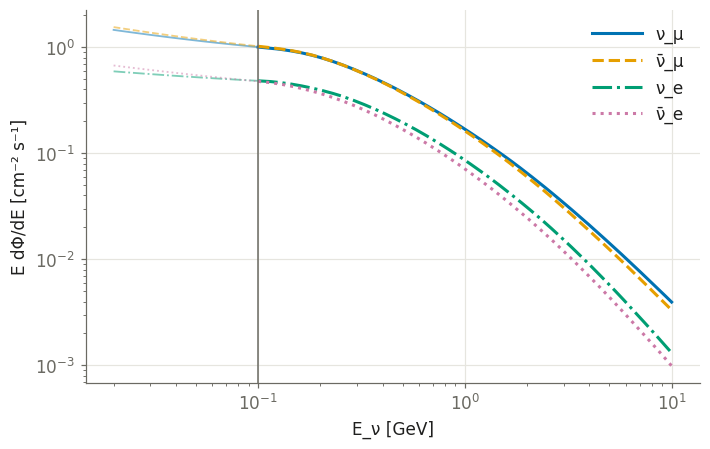

In [2]:
fig, ax = plt.subplots()
E_low = np.logspace(np.log10(20), 2, 30)
for i, (p, lab) in enumerate(FLAVOURS.items()):
    ax.plot(E / 1e3, E * phi["min"][p], **style(i), label=lab)
    low = sum(2 * np.pi * dc * tab["min"].flux(p, E_low, c, extrapolate=True)
              for dc, c in zip(np.diff(tab["min"].cos_edges),
                               0.5 * (tab["min"].cos_edges[1:] + tab["min"].cos_edges[:-1])))
    ax.plot(E_low / 1e3, E_low * low, **style(i), lw=1.2, alpha=0.5)
ax.axvline(0.1, color=MUTED, lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("E_ν [GeV]")
ax.set_ylabel("E dΦ/dE [cm⁻² s⁻¹]")
ax.legend();

In [3]:
def integral(f, lo, hi):
    s = (E >= lo) & (E <= hi)
    trapz = getattr(np, "trapezoid", None) or np.trapz  # numpy < 2 has only trapz
    return trapz(f[s], E[s])

rows = []
for p, lab in FLAVOURS.items():
    rows.append({"flavour": lab,
                 "0.1-1 GeV": integral(phi["min"][p], 100, 1000),
                 "0.1-10 GeV": integral(phi["min"][p], 100, 10000),
                 "solmax / solmin (0.1-10 GeV)": integral(phi["max"][p], 100, 10000) / integral(phi["min"][p], 100, 10000)})
pd.DataFrame(rows).set_index("flavour").round(3)

,0.1-1 GeV,0.1-10 GeV,solmax / solmin (0.1-10 GeV)
flavour,,,
ν_μ,1.353,1.468,0.945
ν̄_μ,1.353,1.460,0.945
ν_e,0.675,0.730,0.939
ν̄_e,0.620,0.664,0.949


Integrated fluxes in cm⁻² s⁻¹. Most of the flux below 10 GeV is below 1 GeV, the region relevant for the DSNB backgrounds. The solar modulation lowers the flux by ~5 % at solar maximum; it is larger at low energy (next figure), so it is a systematic for the NCQE and invisible-muon rates.

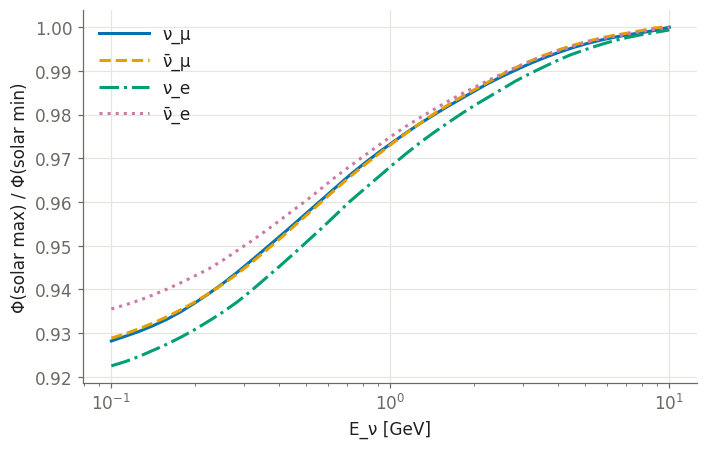

In [4]:
fig, ax = plt.subplots()
for i, (p, lab) in enumerate(FLAVOURS.items()):
    ax.plot(E / 1e3, phi["max"][p] / phi["min"][p], **style(i), label=lab)
ax.set_xscale("log")
ax.set_xlabel("E_ν [GeV]")
ax.set_ylabel("Φ(solar max) / Φ(solar min)")
ax.legend();

## 2. Flavour and ν/ν̄ ratios

Below a few GeV all parent muons decay in the atmosphere, so (ν_μ + ν̄_μ)/(ν_e + ν̄_e) ≈ 2; it grows at higher energy as muons reach the ground.

E = 304 MeV: mu/e = 2.07, nu_e/anti-nu_e = 1.12
E = 1012 MeV: mu/e = 2.11, nu_e/anti-nu_e = 1.21


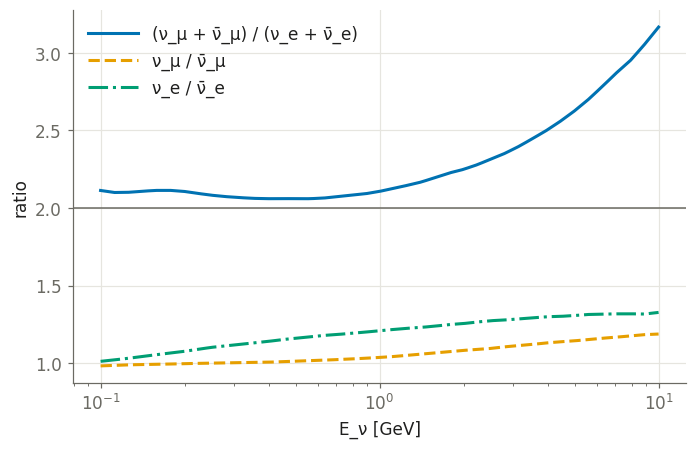

In [5]:
m = phi["min"]
fig, ax = plt.subplots()
ax.plot(E / 1e3, (m[14] + m[-14]) / (m[12] + m[-12]), **style(0), label="(ν_μ + ν̄_μ) / (ν_e + ν̄_e)")
ax.plot(E / 1e3, m[14] / m[-14], **style(1), label="ν_μ / ν̄_μ")
ax.plot(E / 1e3, m[12] / m[-12], **style(2), label="ν_e / ν̄_e")
ax.axhline(2, color=MUTED, lw=1)
ax.set_xscale("log")
ax.set_xlabel("E_ν [GeV]")
ax.set_ylabel("ratio")
ax.legend()
for e0 in (300, 1000):
    i = np.searchsorted(E, e0)
    print(f"E = {E[i]:.0f} MeV: mu/e = {(m[14][i] + m[-14][i]) / (m[12][i] + m[-12][i]):.2f}, "
          f"nu_e/anti-nu_e = {m[12][i] / m[-12][i]:.2f}")

The ν̄_e fraction matters directly: ν̄_e + p → e⁺ + n on free protons is an irreducible IBD with a real neutron, the atmospheric ν̄_e CC background of the DSNB.

## 3. Zenith dependence

At Kamioka the geomagnetic cutoff is high, so at low energy down-going neutrinos (from cosmic rays arriving above Japan) are suppressed compared with up-going ones (from cosmic rays arriving elsewhere on Earth). The effect fades above a few GeV. The peak near the horizon at low energy is the usual path-length effect: horizontal showers develop in thinner air and more of their muons decay before reaching the ground. For a background of a few tens of MeV the direction is not measured, but the zenith distribution enters the oscillation weights.

up/down (nu_mu + anti-nu_mu) at 304 MeV: 1.25


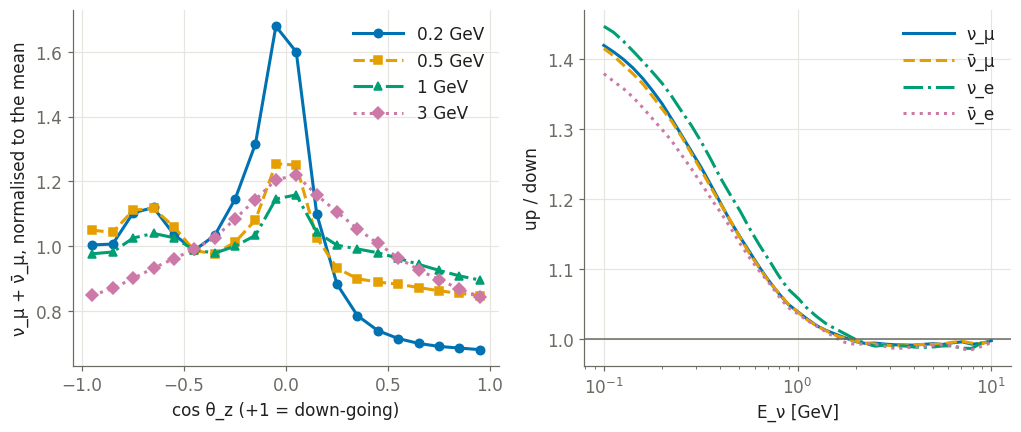

In [6]:
t = tab["min"]
mids = 0.5 * (t.cos_edges[1:] + t.cos_edges[:-1])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for i, e0 in enumerate([200, 500, 1000, 3000]):
    f = np.array([t.flux(14, e0, c)[0] + t.flux(-14, e0, c)[0] for c in mids])
    ax.plot(mids, f / f.mean(), **style(i, marker=True), label=f"{e0 / 1e3:g} GeV")
ax.set_xlabel("cos θ_z (+1 = down-going)")
ax.set_ylabel("ν_μ + ν̄_μ, normalised to the mean")
ax.legend()

up, down = mids < 0, mids > 0
for i, (p, lab) in enumerate(FLAVOURS.items()):
    fu = sum(t.flux(p, E, c) for c in mids[up])
    fd = sum(t.flux(p, E, c) for c in mids[down])
    ax2.plot(E / 1e3, fu / fd, **style(i), label=lab)
ax2.axhline(1, color=MUTED, lw=1)
ax2.set_xscale("log")
ax2.set_xlabel("E_ν [GeV]")
ax2.set_ylabel("up / down")
ax2.legend()
i = np.searchsorted(E, 300)
print(f"up/down (nu_mu + anti-nu_mu) at {E[i]:.0f} MeV: "
      f"{sum(t.flux(14, E[i], c)[0] + t.flux(-14, E[i], c)[0] for c in mids[up]) / sum(t.flux(14, E[i], c)[0] + t.flux(-14, E[i], c)[0] for c in mids[down]):.2f}")

## 4. Which neutrino energies matter, and the gap below 100 MeV

- **Invisible muons (decay-e):** ν_μ CC with a muon below the Cherenkov threshold (kinetic energy < 55 MeV). This needs E_ν ≳ 150 MeV (muon mass plus binding) and is dominated by E_ν ~ 150–400 MeV, inside the table.
- **NCQE:** the knock-out of a nucleon from ¹⁶O has a threshold of ~12–16 MeV of energy transfer and is dominated by E_ν ~ 0.2–1 GeV, but the tail below 100 MeV is not zero.
- **ν_e / ν̄_e CC:** a visible e± of 16–80 MeV needs E_ν ≈ E_e + (a few to ~30) MeV on ¹⁶O, and E_ν ≈ E_e + 1.3 MeV on H. **A large part of this component comes from E_ν < 100 MeV, below the table** (the fraction is to be quantified with the generator).

So the HKKM table is enough for the invisible-muon background and most of the NCQE, but not for ν_e CC in the DSNB window. A dedicated low-energy calculation is needed (FLUKA, Battistoni et al., Astropart. Phys. 23, 526, 2005, which goes down to ~10 MeV), and the difference between it and the extrapolation is a systematic.

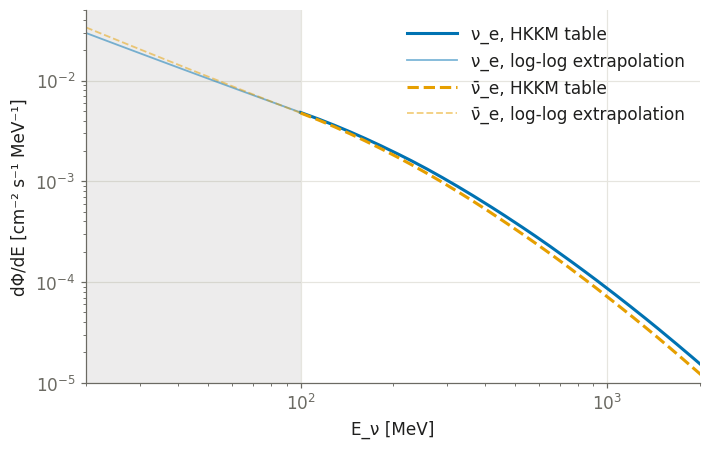

In [7]:
fig, ax = plt.subplots()
for i, p in enumerate([12, -12]):
    hi = phi["min"][p]
    ax.plot(E, hi, **style(i), label=f"{FLAVOURS[p]}, HKKM table")
    lo = sum(2 * np.pi * dc * tab["min"].flux(p, E_low, c, extrapolate=True)
             for dc, c in zip(np.diff(t.cos_edges), mids))
    ax.plot(E_low, lo, **style(i), lw=1.2, alpha=0.5, label=f"{FLAVOURS[p]}, log-log extrapolation")
ax.axvspan(20, 100, color=MUTED, alpha=0.12, lw=0)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(20, 2000)
ax.set_ylim(1e-5, 5e-2)
ax.set_xlabel("E_ν [MeV]")
ax.set_ylabel("dΦ/dE [cm⁻² s⁻¹ MeV⁻¹]")
ax.legend();

Shaded: E_ν = 20–100 MeV, where ν_e CC events in the DSNB window are produced and the table has no values.

## 5. Summary

| Check | Status |
|---|---|
| Reader: units, interpolation, cos θ_z bins | ✓ |
| Integrated flux, flavour ratio ≈ 2, ν/ν̄ | ✓ (values as expected for Kamioka) |
| Solar modulation | ✓ (~5 % lower at maximum, more at low E) |
| Geomagnetic up/down asymmetry | ✓ (strong at Kamioka below a few GeV) |
| Flux below 100 MeV | ✗ **missing**: needed for ν_e CC; FLUKA 2005 to be added |
| Oscillation weights | not yet (step C1) |